# Лабораторная работа 5. Полевой транзистор в цепи амплитудного модулятора (mixed mode)

Нормально открытый MESFET на GaAs работает как нелинейный элемент амплитудного
модулятора. На затвор подаётся сумма постоянного смещения у порога, несущей f₁ и
модулирующего сигнала f₂ = 1 кГц; квадратичный участок ВАХ даёт в токе стока
комбинационные частоты f₁ ± f₂, а колебательный контур в цепи стока выделяет несущую
с боковыми — амплитудно-модулированный сигнал.

Задания:
1. структура транзистора: легирование и сетка;
2. ВАХ: семейства Id(Vd) и Id(Vg), картина тока в канале, пороговое напряжение;
3. транзистор в цепи (смешанный режим: уравнения прибора и цепи решаются вместе),
   переходный процесс 4 мс: сигналы на затворе и ток стока;
4. то же с параллельным RLC-контуром в цепи стока — АМ-сигнал на контуре.

Расчёт идёт в ISE внутри Windows XP, управление — по telnet (`tools/xp.py`). Без
виртуальной машины выполняются все ячейки, кроме помеченных `RUN`: тогда используются
уже выгруженные файлы из `ise/`.

In [1]:
import sys, os, re, time
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "tools")) and ROOT != "/":
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, os.path.join(ROOT, "tools"))
LAB = os.path.join(ROOT, "Lab5_MESFET_mixed_mode")
sys.path.insert(0, LAB)
import numpy as np
from IPython.display import Image, display
import lab5_files as L, make_figures as mf

RUN = False                  # True — пересчитать в ISE, False — взять готовые файлы из ise/
WORK = r"C:\tcad\L5"         # папка внутри Windows
ISE = os.path.join(LAB, "ise")
os.chdir(ISE)
if RUN:
    import xp, put
print(os.getcwd())

/Users/phoenix/Documents/MIET/labs_modelling/Nanostructure_Modelling_Course_MIET_2026/Lab5_MESFET_mixed_mode/ise


In [2]:
# ---- ВАРИАНТ ----
VARIANT = 2
N01 = 8.0e+17        # пик гауссова профиля канала, 1/см3
A01 = 0.05           # его ширина, мкм
F1  = 9e3            # несущая, Гц
UM2 = 0.25           # амплитуда модулирующего сигнала, В
# -----------------
UM1, F2, VD = 0.4, 1e3, 1.0      # амплитуда несущей, частота модуляции, напряжение на стоке
C, R2 = 1.25e-6, 30.0            # ёмкость и сопротивление контура — как в методических указаниях
LIND = L.inductance(F1, C)       # индуктивность под резонанс на несущей
print("L = %.4g Гн, резонанс %.0f Гц" % (LIND, 1 / (2 * np.pi * np.sqrt(LIND * C))))

L = 0.0002502 Гн, резонанс 9000 Гц


## 1. Структура, сетка и легирование

GaAs 4 × 0.36 мкм с двумя ступенями выемки под затвор; затвор — контакт Шоттки
(барьер 0.75 В) шириной 0.5 мкм на глубине 0.08 мкм. Легирование фосфором вместо
кремния: 10¹⁴ см⁻³ однородно, гауссов канал N₀₁·exp(−(y − 0.1157)²/a₀₁²) и гауссовы
омические области 3·10¹⁸ см⁻³ у поверхности. Неполная ионизация: у фосфора задана
энергия кремния в GaAs, 6 мэВ (`Ion.par`). Сетка — две области сгущения, общая и у канала.

In [3]:
def write(name, text, crlf=False):
    """Записать файл и сообщить, совпал ли он с прежним."""
    old = open(name, newline="").read() if os.path.exists(name) else None
    new = text.replace("\n", "\r\n") if crlf else text
    os.makedirs(os.path.dirname(name) or ".", exist_ok=True)
    with open(name, "w", newline="") as f:
        f.write(new)
    return "без изменений" if old == new else "ОБНОВЛЁН" if old else "создан"

T2 = {"t.bnd": L.BND, "t.cmd": L.cmd(N01, A01), "Ion.par": L.ION_PAR,
      "t_gate_des.cmd": L.des_gate(VD), "t_family_2_des.cmd": L.des_family2(mf.VD_FAMILY),
      "t_family_des.cmd": L.des_family(mf.VG_FAMILY), "t_des.cmd": L.des_family((0.8,))}
for f, text in T2.items():
    print("task2/%-20s %s" % (f, write("task2/" + f, text)))

task2/t.bnd                без изменений
task2/t.cmd                без изменений
task2/Ion.par              без изменений
task2/t_gate_des.cmd       без изменений
task2/t_family_2_des.cmd   без изменений
task2/t_family_des.cmd     без изменений
task2/t_des.cmd            без изменений


## 2. ВАХ и порог

Порог — по методике работы 4: максимум второй производной Id(Vg) в «пятке» ВАХ при
Vd = 1 В; касательная в этой точке даёт близкое значение, и порогом, как допускают
указания, берётся сама точка максимума. Он же — постоянное смещение затвора в цепи.

Четыре прогона на одной сетке: Id(Vg) при Vd = 1 В (для порога), семейство Id(Vg) при
Vd = 0.1…2 В, семейство Id(Vd) при Vg = 0.8…−2.4 В и отдельный прогон до Vg = 0.8 В,
Vd = 2 В — для картины тока в канале. Командные файлы Sentaurus 2012 из примера ISE 7.0
принимает без изменений.

In [4]:
def queue(bat):
    """Поставить командный файл в очередь at через 2 минуты."""
    now = xp.run(["time /t"]).split("time /t")[-1]
    hh, mm = map(int, re.search(r"(\d{1,2}):(\d{2})", now).groups())
    mm += 2; hh = (hh + mm // 60) % 24; mm %= 60
    xp.run(["at /delete /yes", r"at %02d:%02d cmd /c %s\%s" % (hh, mm, WORK, bat)])

def wait(flag):
    while "ALL DONE" not in xp.run([r"type %s\%s" % (WORK, flag)]):
        time.sleep(120)

if RUN:
    cmds = [r"mkdir %s" % WORK, r"mkdir %s\task2" % WORK]
    for f in T2:
        cmds += put.commands_for("task2/" + f, r"%s\task2\%s" % (WORK, f))
    cmds += put.commands_for("runA.bat", WORK + r"\runA.bat")
    xp.run(cmds, total=3000)
    queue("runA.bat"); wait("pA.txt")
    for f in ["t_msh.grd", "t_msh.dat", "t_des.dat", "New_t_des.plt"] + \
             ["Vg_%s_t_des.plt" % mf.tag_vg(v) for v in mf.VG_FAMILY] + \
             ["Vd_%03d_t_des.plt" % round(v * 100) for v in mf.VD_FAMILY]:
        xp.fetch(r"%s\task2\%s" % (WORK, f), "task2/" + f)

In [5]:
import viz
g = viz.read_plt("task2/New_t_des.plt")
Vg, Id = np.asarray(g["gate OuterVoltage"]), np.asarray(g["drain TotalCurrent"])
VT, VT_TAN = mf.threshold(Vg, Id)
print("Id(Vg) при Vd = 1 В: %d точек, Vg = %.1f…%.1f В, максимум %.3f А/мм" % (len(Vg), Vg.min(), Vg.max(), Id.max()))
print("порог: максимум второй производной VT = %.2f В, по касательной %.2f В (на эталоне смещение −5.60 В)" % (VT, VT_TAN))

Id(Vg) при Vd = 1 В: 107 точек, Vg = -10.0…2.0 В, максимум 0.446 А/мм
порог: максимум второй производной VT = -5.63 В, по касательной -5.71 В (на эталоне смещение −5.60 В)


## 3. Транзистор в цепи

На затвор — сумма источников v1 = VT (постоянный), v2 = UM1·sin(2πF1·t) и
v3 = UM2·sin(2πF2·t); на сток — 1 В, в цепи истока — резистор 1 Ом. Переходный процесс
0…4 мс с шагом до 20 мкс. В задании 4 сток питается через параллельный контур R2, C, L
с резонансом на несущей.

In [6]:
VT_CIRCUIT = round(VT, 2)
T3 = {"t.bnd": L.BND, "t.cmd": L.cmd(N01, A01), "Ion.par": L.ION_PAR,
      "t_circuit_des.cmd": L.des_circuit(VT_CIRCUIT, F1, UM2, UM1, F2, VD)}
T4 = dict(T3); del T4["t_circuit_des.cmd"]
T4["t_circuit2_des.cmd"] = L.des_circuit(VT_CIRCUIT, F1, UM2, UM1, F2, VD, rlc=(R2, C, LIND))
for d, files in (("task3", T3), ("task4", T4)):
    for f, text in files.items():
        print("%s/%-20s %s" % (d, f, write(d + "/" + f, text)))
print(T4["t_circuit2_des.cmd"][T4["t_circuit2_des.cmd"].index("System"):T4["t_circuit2_des.cmd"].index("Plot {")])

task3/t.bnd                без изменений
task3/t.cmd                без изменений
task3/Ion.par              без изменений
task3/t_circuit_des.cmd    без изменений
task4/t.bnd                без изменений
task4/t.cmd                без изменений
task4/Ion.par              без изменений
task4/t_circuit2_des.cmd   без изменений
System {
	Vsource_pset v1 (n1 n0) { dc = -5.63 }
	Vsource_pset v2 (n2 n1) { sine = ( 0.0 0.4 9000 0.0 0.0) }
	Vsource_pset v3 (n3 n2) { sine = ( 0.0 0.25 1000 0.0 0.0) }
	Vsource_pset v4 (n6 n0) { dc = 1 }
	Resistor_pset r (n5 n0) { resistance = 1 }
	Resistor_pset r1 (n4 n6) { resistance = 30 }
	Capacitor_pset c (n4 n6) { capacitance = 1.25e-06 }
	Inductor_pset l (n4 n6) { inductance = 0.0002502 }
	MESFET fet ( "source"=n5 "gate"=n3 "drain"=n4 )
	Set (n0 = 0)
	Set (n5 = 0.0)
	Plot "nodes.plt" (time() n0 n1 n2 n3 n4 n5 n6)
}




In [7]:
if RUN:
    bat = ["@echo off", r"echo START > %s\pB.txt" % WORK]
    for d, des in (("task3", "t_circuit_des.cmd"), ("task4", "t_circuit2_des.cmd")):
        bat += [r"cd /d %s\%s" % (WORK, d), r"C:\ISE\bin\mesh -t t > m.log 2>&1",
                r"C:\ISE\bin\dessis %s > run.log 2>&1" % des, r"echo %s >> %s\pB.txt" % (d, WORK)]
    bat += [r"echo ALL DONE >> %s\pB.txt" % WORK]
    write("runB.bat", "\n".join(bat) + "\n", crlf=True)
    cmds = []
    for d, files in (("task3", T3), ("task4", T4)):
        cmds.append(r"mkdir %s\%s" % (WORK, d))
        for f in files:
            cmds += put.commands_for(d + "/" + f, r"%s\%s\%s" % (WORK, d, f))
    cmds += put.commands_for("runB.bat", WORK + r"\runB.bat")
    xp.run(cmds, total=3000)
    queue("runB.bat"); wait("pB.txt")
    for d in ("task3", "task4"):
        for f in ("New_nodes.plt", "New_fet_des.plt"):
            xp.fetch(r"%s\%s\%s" % (WORK, d, f), d + "/" + f)

## 4. Иллюстрации

Графики строятся в размере, рамке и пределах осей эталонных иллюстраций, в стиле
Svisual (`ise_style.xy_svisual`); карты — 30 полос палитры Svisual.

построено: ['z1_легирование', 'z1_сетка', 'z2_вах_IdVg']


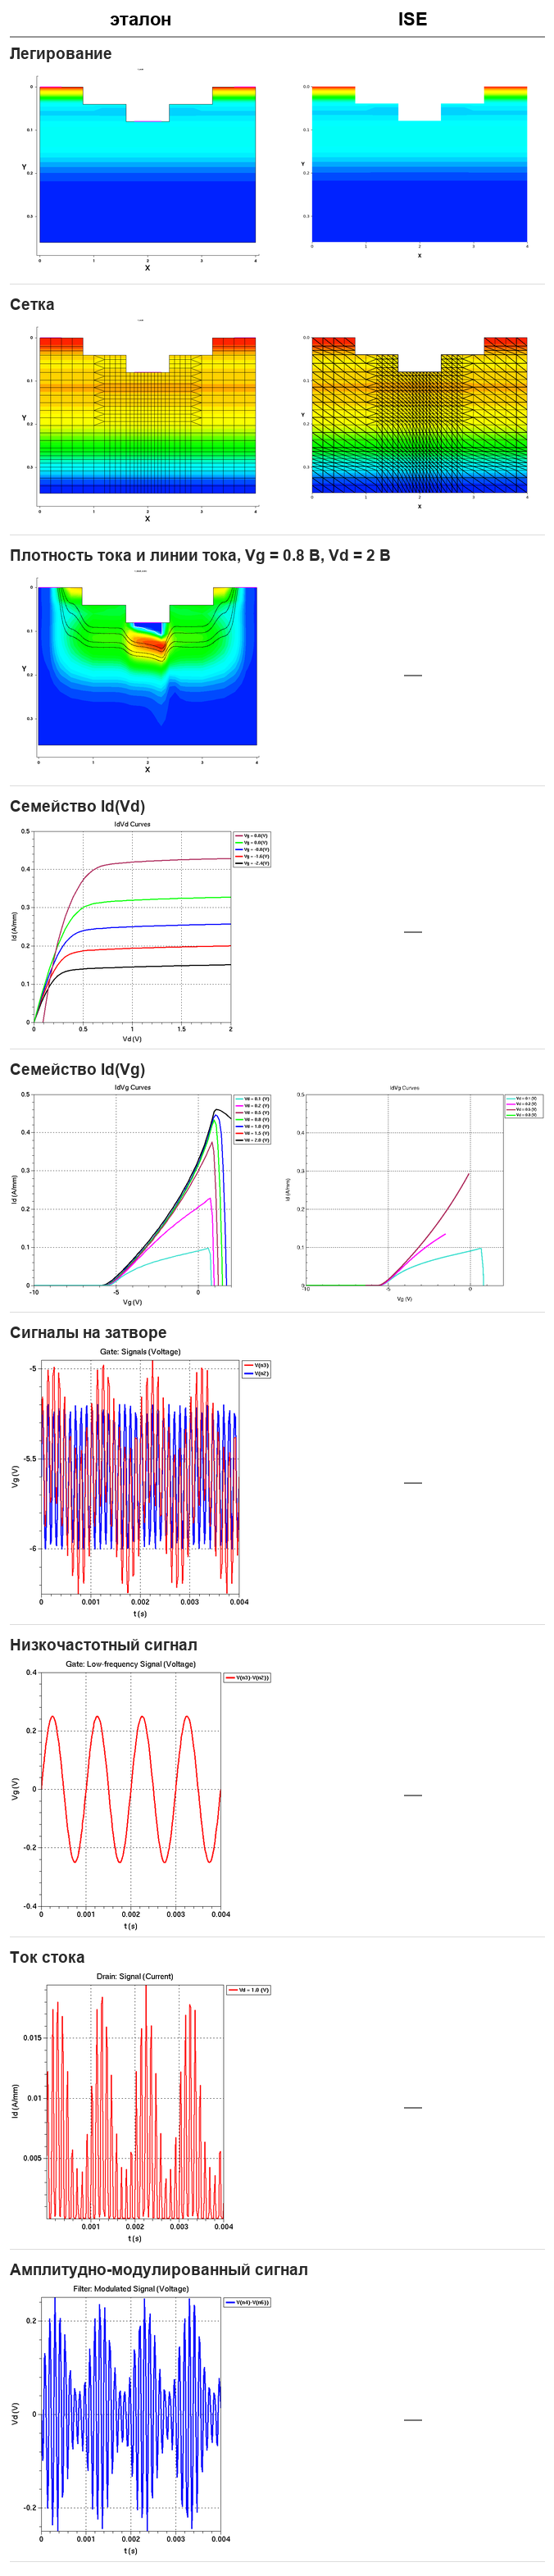

In [8]:
print("построено:", mf.figures())
mf.comparison_grid()
display(Image(os.path.join(LAB, "results", "сравнение.png")))

### Вывод

_(нелинейное преобразование сигналов на квадратичном участке ВАХ, спектр тока стока, АМ-сигнал на контуре)_